In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/matching/D8/'

In [2]:
df_cosine = pd.read_csv(main_dir + 'cosine.csv')
df_cosine['similarity'] = 'cosine'
df_dice = pd.read_csv(main_dir + 'dice.csv')
df_dice['similarity'] = 'dice'
df_jaccard = pd.read_csv(main_dir + 'jaccard.csv')
df_jaccard['similarity'] = 'jaccard'
#df_scm = pd.read_csv(main_dir + 'scm.csv')
#df_scm['similarity'] = 'scm'

In [3]:
result = pd.DataFrame()
dfs = [df_cosine, df_dice, df_jaccard]#, df_scm]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Matching with cosine,537421,0.25,0.16,99.06,0.31,845,536576,23761,8,cosine,[title],1024,0,1,salted_qgrams,,4
1,Matching with cosine,268687,0.30,0.31,98.24,0.62,838,267849,23754,15,cosine,[title],1024,0,1,salted_qgrams,,4
2,Matching with cosine,28519,0.50,2.63,87.81,5.10,749,27770,23665,104,cosine,[title],1024,0,1,salted_qgrams,,4
3,Matching with cosine,49274,0.45,1.59,92.03,3.13,785,48489,23701,68,cosine,[title],1024,0,1,salted_qgrams,,4
4,Matching with cosine,86142,0.40,0.93,94.37,1.85,805,85337,23721,48,cosine,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1819,Matching with jaccard,803015,0.75,0.06,52.87,0.11,451,802564,23367,402,jaccard,[title],1024,0,32,salted_qgrams,,4
1820,Matching with jaccard,234658,0.80,0.15,41.97,0.30,358,234300,23274,495,jaccard,[title],1024,0,32,salted_qgrams,,4
1821,Matching with jaccard,53853,0.85,0.45,28.49,0.89,243,53610,23159,610,jaccard,[title],1024,0,32,salted_qgrams,,4
1822,Matching with jaccard,8961,0.90,1.65,17.35,3.02,148,8813,23064,705,jaccard,[title],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[title]    1824
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    1824
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    1824
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    1824
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    1824
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     57
2     57
3     57
4     57
5     57
6     57
7     57
8     57
9     57
10    57
11    57
12    57
13    57
14    57
15    57
16    57
17    57
18    57
19    57
20    57
21    57
22    57
23    57
24    57
25    57
26    57
27    57
28    57
29    57
30    57
31    57
32    57
Name: count, dtype: int64

In [10]:
max_f1 = result.loc[result.groupby(['num_hashes','similarity'])['F1 %'].idxmax()]
max_f1

,name,total_matches,similarity_threshold,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
11,Matching with cosine,1286,0.80,25.82,38.92,31.04,332,954,23248,521,cosine,[title],1024,0,1,salted_qgrams,,4
617,Matching with dice,1238,0.80,25.93,37.63,30.70,321,917,23237,532,dice,[title],1024,0,1,salted_qgrams,,4
1223,Matching with jaccard,942,0.70,29.19,32.24,30.64,275,667,23191,578,jaccard,[title],1024,0,1,salted_qgrams,,4
31,Matching with cosine,739,0.85,32.75,28.37,30.40,242,497,23158,611,cosine,[title],1024,0,2,salted_qgrams,,4
637,Matching with dice,1313,0.80,24.52,37.75,29.73,322,991,23238,531,dice,[title],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1196,Matching with dice,5467,0.95,2.47,15.83,4.27,135,5332,23051,718,dice,[title],1024,0,31,salted_qgrams,,4
1804,Matching with jaccard,414,0.95,17.87,8.68,11.68,74,340,22990,779,jaccard,[title],1024,0,31,salted_qgrams,,4
607,Matching with cosine,7555,0.95,1.85,16.41,3.33,140,7415,23056,713,cosine,[title],1024,0,32,salted_qgrams,,4
1215,Matching with dice,7439,0.95,1.87,16.30,3.35,139,7300,23055,714,dice,[title],1024,0,32,salted_qgrams,,4


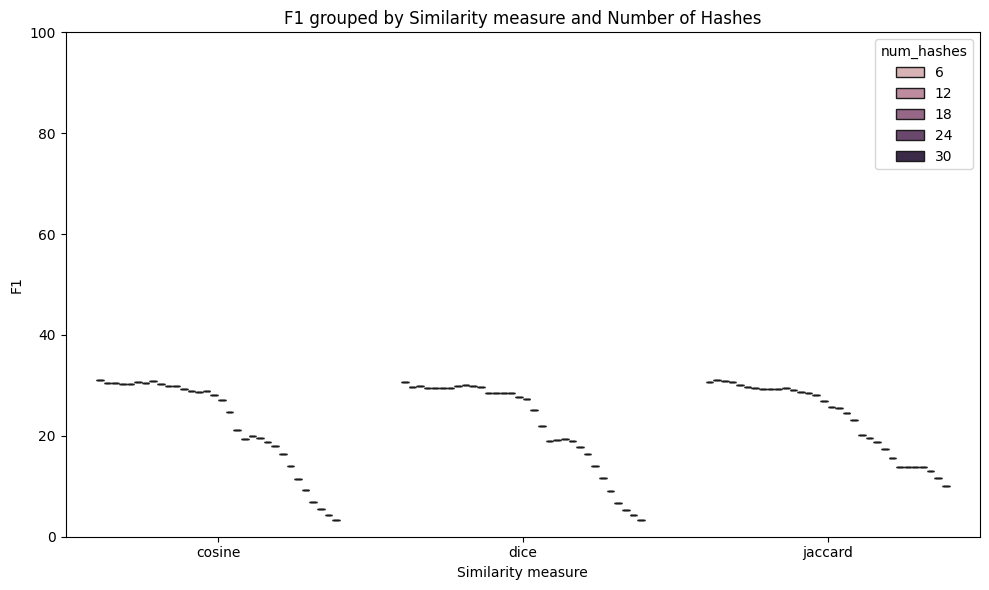

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="similarity",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by Similarity measure and Number of Hashes")
plt.xlabel("Similarity measure")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [12]:
metrics_df = max_f1.melt(
    id_vars=["similarity", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,similarity,num_hashes,Metric,Score
0,cosine,1,Precision %,25.82
1,dice,1,Precision %,25.93
2,jaccard,1,Precision %,29.19
3,cosine,2,Precision %,32.75
4,dice,2,Precision %,24.52
...,...,...,...,...
283,dice,31,F1 %,4.27
284,jaccard,31,F1 %,11.68
285,cosine,32,F1 %,3.33
286,dice,32,F1 %,3.35


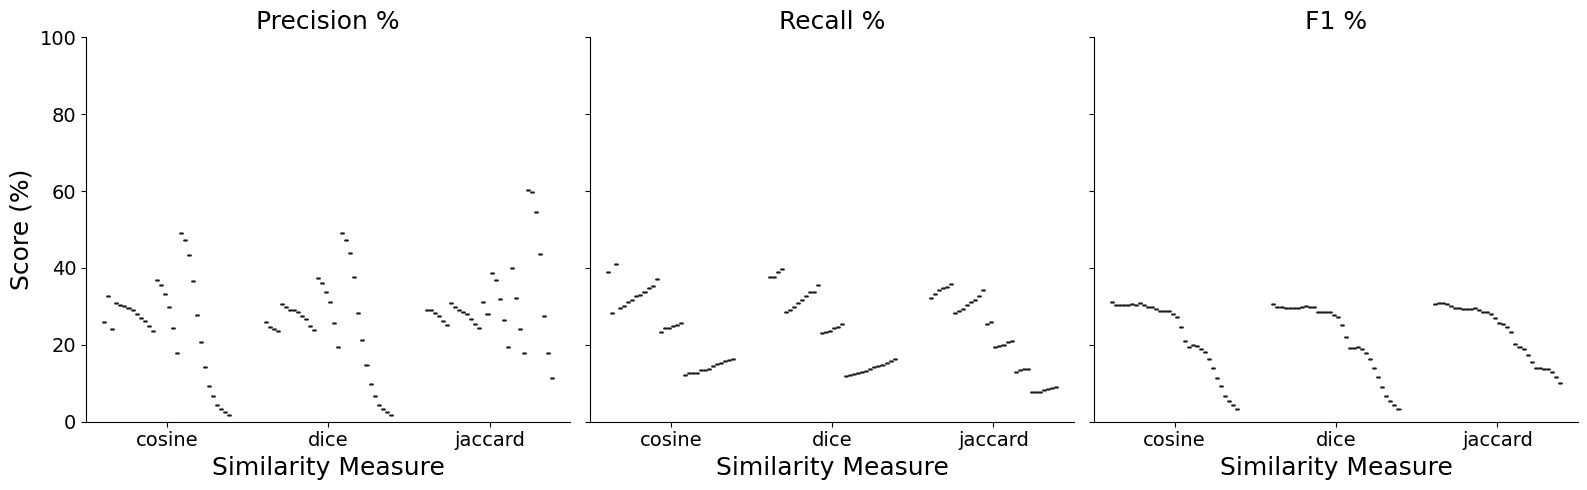

In [13]:
g = sns.catplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("Similarity Measure", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

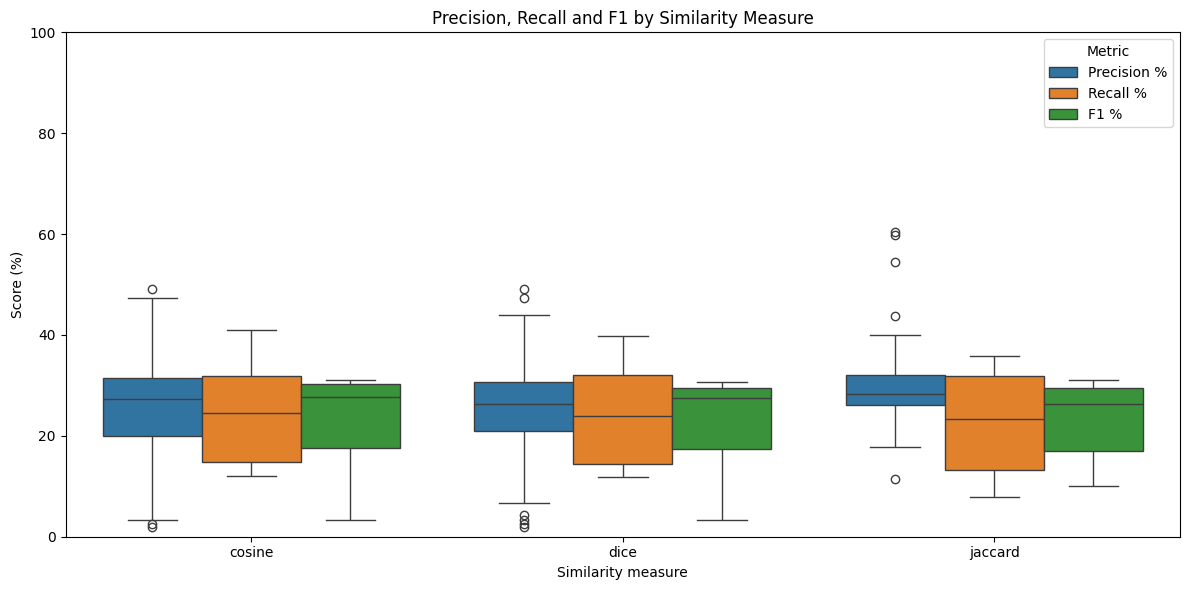

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by Similarity Measure")
plt.xlabel("Similarity measure")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()